## Main Question: finding the best value for your home

In [1]:
# Code Block 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Code Block 2
df = pd.read_csv('housing.csv', index_col = 0, header = 0)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1460 entries, 1 to 1460
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt    

In [3]:
# Code Block 3
df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
# Code Block 4
df.isnull().sum()[df.isnull().sum() > 0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [5]:
# Code Block 5: dropping mostly empty or duplicate columns
df1 = df.drop(columns=['Alley', 'PoolQC', 'Fence', 'MiscFeature', 'OverallQual', 'ExterQual', '1stFlrSF', '2ndFlrSF', 'GarageQual', '1stFlrSF', '2ndFlrSF', 'MasVnrType', 'FireplaceQu', 'LowQualFinSF'])

In [6]:
# Code Block 6
df1.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,...,0,0,0,0,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,272,0,0,0,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,...,0,0,0,0,0,12,2008,WD,Normal,250000


In [7]:
# Code Block 7: filling emtpy values with the median
df1['LotFrontage'] = df1['LotFrontage'].fillna(df1['LotFrontage'].median())
df1['MasVnrArea'] = df1['MasVnrArea'].fillna(df1['MasVnrArea'].median())
df1['GarageYrBlt'] = df1['GarageYrBlt'].fillna(df1['GarageYrBlt'].median())

In [8]:
# Code Block 8: finding value counts of columns with non number values
print(df['MSZoning'].value_counts())
print(df['Street'].value_counts())
print(df['LotShape'].value_counts())
print(df['LandContour'].value_counts())
print(df['Utilities'].value_counts())
print(df['LotConfig'].value_counts())
print(df['LandSlope'].value_counts())
print(df['Condition1'].value_counts())
print(df['Condition2'].value_counts())
print(df['BldgType'].value_counts())
print(df['LandContour'].value_counts())
print(df['HouseStyle'].value_counts())
print(df['RoofStyle'].value_counts())
print(df['RoofMatl'].value_counts())
print(df['Exterior1st'].value_counts())
print(df['Exterior2nd'].value_counts())
print(df['ExterCond'].value_counts())
print(df['Foundation'].value_counts())
print(df['BsmtCond'].value_counts())
print(df['BsmtExposure'].value_counts())
print(df['BsmtFinType1'].value_counts())
print(df['BsmtFinType2'].value_counts())
print(df['Heating'].value_counts())
print(df['HeatingQC'].value_counts())
print(df['CentralAir'].value_counts())
print(df['Electrical'].value_counts())
print(df['KitchenQual'].value_counts())
print(df['Functional'].value_counts())
print(df['GarageType'].value_counts())
print(df['GarageFinish'].value_counts())
print(df['GarageCond'].value_counts())
print(df['SaleType'].value_counts())
print(df['SaleCondition'].value_counts())
print(df['Neighborhood'].value_counts())

MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64
Street
Pave    1454
Grvl       6
Name: count, dtype: int64
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64
LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64
Condition1
Norm      1260
Feedr       81
Artery      48
RRAn        26
PosN        19
RRAe        11
PosA         8
RRNn         5
RRNe         2
Name: count, dtype: int64
Condition2
Norm      1445
Feedr        6
Artery       2
RRNn         2
PosN         2
PosA         1
RRAn         1
RRAe         1
Name: count, dtype: int64
BldgType
1Fam      1220
TwnhsE     114
Duplex      52
Twnhs       43
2fmCon   

In [9]:
# Code Block 9: creating dummy variables
df1 = pd.get_dummies(df1, columns=['Neighborhood'], drop_first=True)
df1 = pd.get_dummies(df1, columns=['MSZoning'], drop_first=True)
df1 = pd.get_dummies(df1, columns=['LotShape'], drop_first=True)
df1 = pd.get_dummies(df1, columns=['HouseStyle'], drop_first=True)
df1 = pd.get_dummies(df1, columns=['Foundation'], drop_first=True)
df1 = pd.get_dummies(df1, columns=['GarageType'], drop_first=True)
df1 = pd.get_dummies(df1, columns=['SaleCondition'], drop_first=True)

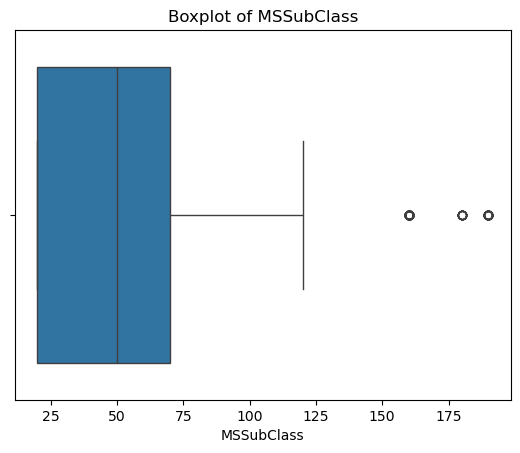

In [10]:
# Code Block 10: finding outliers using box plots, treat as nominal
plt.figure()

sns.boxplot(x=df['MSSubClass'])

plt.title("Boxplot of MSSubClass")

plt.show()

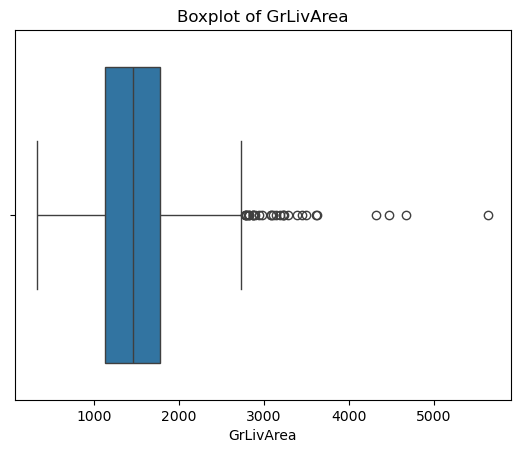

In [11]:
# Code Block 11: finding outliers using box plots
plt.figure()

sns.boxplot(x=df['GrLivArea'])

plt.title("Boxplot of GrLivArea")

plt.show()

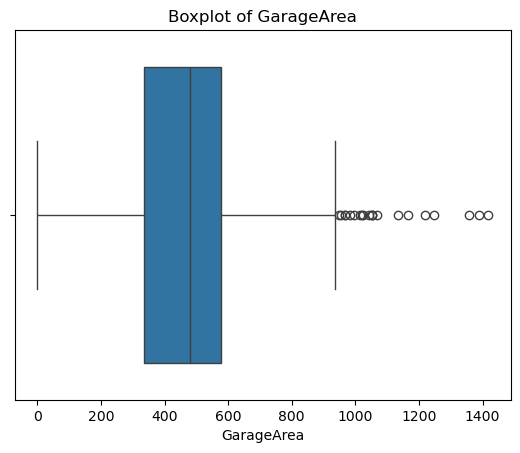

In [12]:
# Code Block 12: finding outliers using box plots
plt.figure()

sns.boxplot(x=df['GarageArea'])

plt.title("Boxplot of GarageArea")

plt.show()

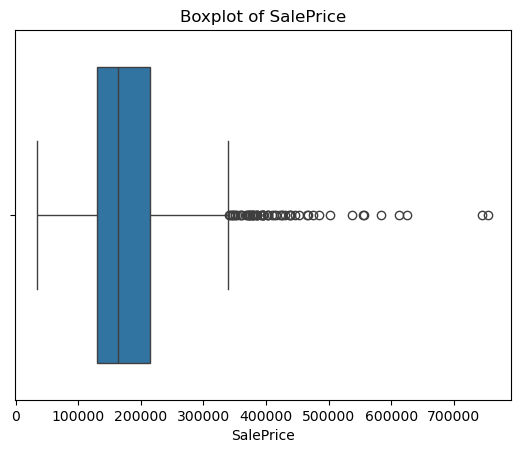

In [13]:
# Code Block 13: finding outliers using box plots
plt.figure()

sns.boxplot(x=df['SalePrice'])

plt.title("Boxplot of SalePrice")

plt.show()

In [14]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1460 entries, 1 to 1460
Columns: 114 entries, MSSubClass to SaleCondition_Partial
dtypes: bool(53), float64(3), int64(30), object(28)
memory usage: 782.8+ KB


In [15]:
# Code Block 14: seeing if anything is correlated with saleprice
correlated = df1.corr(numeric_only=True)["SalePrice"].sort_values()
print(correlated.head(10))

GarageType_Detchd      -0.354141
Foundation_CBlock      -0.343263
MSZoning_RM            -0.288065
LotShape_Reg           -0.267672
Neighborhood_OldTown   -0.192189
Neighborhood_NAmes     -0.188513
Neighborhood_Edwards   -0.179949
Neighborhood_IDOTRR    -0.164056
SaleCondition_Normal   -0.153990
Neighborhood_BrkSide   -0.143648
Name: SalePrice, dtype: float64


In [16]:
# negative values are bad predictors, and dummy variables

In [17]:
# Code Block 15: seeing if anything is correlated with saleprice
print(correlated.tail(10))

Foundation_PConc    0.497734
YearRemodAdd        0.507101
YearBuilt           0.522897
TotRmsAbvGrd        0.533723
FullBath            0.560664
TotalBsmtSF         0.613581
GarageArea          0.623431
GarageCars          0.640409
GrLivArea           0.708624
SalePrice           1.000000
Name: SalePrice, dtype: float64


In [18]:
# closer to 1 is a higher correlation

In [19]:
# Code Block 16: checking for multicollinearity
df_numeric = df1.select_dtypes(include='number').drop(columns=['SalePrice'])
print(df_numeric.shape)
print(df_numeric.dtypes)

(1460, 32)
MSSubClass         int64
LotFrontage      float64
LotArea            int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
MasVnrArea       float64
BsmtFinSF1         int64
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
GrLivArea          int64
BsmtFullBath       int64
BsmtHalfBath       int64
FullBath           int64
HalfBath           int64
BedroomAbvGr       int64
KitchenAbvGr       int64
TotRmsAbvGrd       int64
Fireplaces         int64
GarageYrBlt      float64
GarageCars         int64
GarageArea         int64
WoodDeckSF         int64
OpenPorchSF        int64
EnclosedPorch      int64
3SsnPorch          int64
ScreenPorch        int64
PoolArea           int64
MiscVal            int64
MoSold             int64
YrSold             int64
dtype: object


In [20]:
# Code Block 17
print(df1.select_dtypes(include='object').columns)

Index(['Street', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
       'Condition1', 'Condition2', 'BldgType', 'RoofStyle', 'RoofMatl',
       'Exterior1st', 'Exterior2nd', 'ExterCond', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'GarageFinish',
       'GarageCond', 'PavedDrive', 'SaleType'],
      dtype='object')


In [21]:
# Code Block 18
numeric_cols = df1.select_dtypes(exclude=["object", "category"]).columns
print(numeric_cols)

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallCond', 'YearBuilt',
       'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
       'TotalBsmtSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice', 'Neighborhood_Blueste',
       'Neighborhood_BrDale', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr',
       'Neighborhood_CollgCr', 'Neighborhood_Crawfor', 'Neighborhood_Edwards',
       'Neighborhood_Gilbert', 'Neighborhood_IDOTRR', 'Neighborhood_MeadowV',
       'Neighborhood_Mitchel', 'Neighborhood_NAmes', 'Neighborhood_NPkVill',
       'Neighborhood_NWAmes', 'Neighborhood_NoRidge', 'Neighborhood_NridgHt',
       'Neighborhood_OldTown', 'Neighborhood_SWISU', 'Neighborhood_Sawyer',
   

In [22]:
# Code Block 19
print(numeric_cols.shape)

(86,)


In [23]:
# Code Block 20
X = df1.select_dtypes(exclude=["object", "category"]).drop(columns=['SalePrice'])
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1460 entries, 1 to 1460
Data columns (total 85 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   MSSubClass             1460 non-null   int64  
 1   LotFrontage            1460 non-null   float64
 2   LotArea                1460 non-null   int64  
 3   OverallCond            1460 non-null   int64  
 4   YearBuilt              1460 non-null   int64  
 5   YearRemodAdd           1460 non-null   int64  
 6   MasVnrArea             1460 non-null   float64
 7   BsmtFinSF1             1460 non-null   int64  
 8   BsmtFinSF2             1460 non-null   int64  
 9   BsmtUnfSF              1460 non-null   int64  
 10  TotalBsmtSF            1460 non-null   int64  
 11  GrLivArea              1460 non-null   int64  
 12  BsmtFullBath           1460 non-null   int64  
 13  BsmtHalfBath           1460 non-null   int64  
 14  FullBath               1460 non-null   int64  
 15  HalfBath 

In [24]:
# Code Block 21: filling emtpy values with the median
X['LotFrontage'] = df1['LotFrontage'].fillna(df1['LotFrontage'].median())
X['MasVnrArea'] = df1['MasVnrArea'].fillna(df1['MasVnrArea'].median())
X['GarageYrBlt'] = df1['GarageYrBlt'].fillna(df1['GarageYrBlt'].median())
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1460 entries, 1 to 1460
Data columns (total 85 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   MSSubClass             1460 non-null   int64  
 1   LotFrontage            1460 non-null   float64
 2   LotArea                1460 non-null   int64  
 3   OverallCond            1460 non-null   int64  
 4   YearBuilt              1460 non-null   int64  
 5   YearRemodAdd           1460 non-null   int64  
 6   MasVnrArea             1460 non-null   float64
 7   BsmtFinSF1             1460 non-null   int64  
 8   BsmtFinSF2             1460 non-null   int64  
 9   BsmtUnfSF              1460 non-null   int64  
 10  TotalBsmtSF            1460 non-null   int64  
 11  GrLivArea              1460 non-null   int64  
 12  BsmtFullBath           1460 non-null   int64  
 13  BsmtHalfBath           1460 non-null   int64  
 14  FullBath               1460 non-null   int64  
 15  HalfBath 

In [25]:
# Code Block 22: checking we have no empty values
print(X.isnull().sum().sum())

0


In [26]:
# Code Block 23: creating our 'y'
y = df1["SalePrice"]

In [27]:
# Code Block 24
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [28]:
# Code Block 25
X = X.astype(float)

In [29]:
# Code Block 26
X_vif = X.copy()

In [30]:
# Code Block 27
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns

In [31]:
# Code Block 28
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [32]:
# Code Block 29: finding my problem features
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

               feature           VIF
8           BsmtFinSF2           inf
9            BsmtUnfSF           inf
10         TotalBsmtSF           inf
7           BsmtFinSF1           inf
31              YrSold  5.551579e+04
4            YearBuilt  4.189291e+04
20         GarageYrBlt  2.976405e+04
5         YearRemodAdd  2.509459e+04
58         MSZoning_RL  1.826250e+02
11           GrLivArea  9.536032e+01
18        TotRmsAbvGrd  9.432625e+01
17        KitchenAbvGr  4.719044e+01
3          OverallCond  4.625727e+01
21          GarageCars  4.395825e+01
22          GarageArea  3.789371e+01
16        BedroomAbvGr  3.562910e+01
14            FullBath  3.077403e+01
59         MSZoning_RM  3.037488e+01
75   GarageType_Attchd  2.413094e+01
43  Neighborhood_NAmes  2.107220e+01


In [33]:
# Found that the basement features are highly correlated

In [34]:
# Code Block 30: dropping highly correlated features, except for TotalBsmtSF
X = X.drop(columns=["BsmtFinSF2", "BsmtUnfSF", "BsmtFinSF1"])

In [35]:
# Code Block 31: running my new vif
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature           VIF
28                YrSold  55500.567698
4              YearBuilt  41824.007732
17           GarageYrBlt  29746.941942
5           YearRemodAdd  24958.709779
55           MSZoning_RL    182.515487
8              GrLivArea     94.839195
15          TotRmsAbvGrd     94.162667
14          KitchenAbvGr     47.069529
3            OverallCond     46.037194
18            GarageCars     43.757278
19            GarageArea     37.763784
13          BedroomAbvGr     35.241248
11              FullBath     30.760352
7            TotalBsmtSF     30.658698
56           MSZoning_RM     30.347771
72     GarageType_Attchd     24.069975
40    Neighborhood_NAmes     20.882535
1            LotFrontage     19.993432
45  Neighborhood_OldTown     14.989940
53           MSZoning_FV     14.758646


In [36]:
# There was multicollinearity within the basement variables

In [37]:
# Code Block 32: continue to drop variables and running the vif again...
X = X.drop(columns=["YrSold"])

In [38]:
# Code Block 33
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature           VIF
4              YearBuilt  29477.955736
17           GarageYrBlt  25641.170591
5           YearRemodAdd  21601.194326
54           MSZoning_RL    180.314750
15          TotRmsAbvGrd     94.159706
8              GrLivArea     94.122745
14          KitchenAbvGr     46.335145
3            OverallCond     45.953791
18            GarageCars     43.638621
19            GarageArea     37.247105
13          BedroomAbvGr     35.102957
7            TotalBsmtSF     30.411677
55           MSZoning_RM     30.280890
11              FullBath     28.892045
71     GarageType_Attchd     23.660919
1            LotFrontage     19.893892
39    Neighborhood_NAmes     19.649635
52           MSZoning_FV     14.643907
79  SaleCondition_Normal     14.250896
44  Neighborhood_OldTown     13.077656


In [39]:
# Code Block 34
X = X.drop(columns=["YearBuilt"])

In [40]:
# Code Block 35
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature           VIF
4           YearRemodAdd  16724.501289
16           GarageYrBlt  15586.085400
53           MSZoning_RL    179.560591
14          TotRmsAbvGrd     93.871151
7              GrLivArea     93.217575
13          KitchenAbvGr     46.332302
17            GarageCars     43.631262
3            OverallCond     42.163423
18            GarageArea     36.770190
12          BedroomAbvGr     34.858624
54           MSZoning_RM     30.068963
6            TotalBsmtSF     29.871570
10              FullBath     28.780490
70     GarageType_Attchd     20.767594
1            LotFrontage     19.870308
38    Neighborhood_NAmes     19.631961
51           MSZoning_FV     14.598428
78  SaleCondition_Normal     14.209437
43  Neighborhood_OldTown     12.855705
31  Neighborhood_CollgCr     12.417766


In [41]:
# Code Block 36
X = X.drop(columns=["YearRemodAdd"])

In [42]:
# Code Block 37
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature         VIF
15           GarageYrBlt  483.401661
52           MSZoning_RL  178.088817
13          TotRmsAbvGrd   93.845165
6              GrLivArea   92.096374
12          KitchenAbvGr   46.331278
16            GarageCars   43.382368
3            OverallCond   35.804127
17            GarageArea   34.854089
11          BedroomAbvGr   34.799934
53           MSZoning_RM   29.911645
5            TotalBsmtSF   29.860653
9               FullBath   28.780237
1            LotFrontage   19.837491
37    Neighborhood_NAmes   19.587248
69     GarageType_Attchd   19.566019
50           MSZoning_FV   14.528779
77  SaleCondition_Normal   14.207582
42  Neighborhood_OldTown   12.698106
30  Neighborhood_CollgCr   12.384471
58     HouseStyle_1Story   11.524275


In [43]:
# Code Block 38
X = X.drop(columns=["GarageYrBlt"])

In [44]:
# Code Block 39
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature         VIF
51           MSZoning_RL  108.612653
6              GrLivArea   92.009619
13          TotRmsAbvGrd   91.706953
12          KitchenAbvGr   46.239109
15            GarageCars   43.162620
16            GarageArea   34.829161
11          BedroomAbvGr   34.682613
3            OverallCond   34.055801
5            TotalBsmtSF   29.799247
9               FullBath   28.524577
52           MSZoning_RM   20.318404
1            LotFrontage   19.706471
68     GarageType_Attchd   19.182248
36    Neighborhood_NAmes   15.500175
76  SaleCondition_Normal   14.131309
57     HouseStyle_1Story   10.820841
49           MSZoning_FV   10.474030
64      Foundation_PConc   10.201175
29  Neighborhood_CollgCr    9.492528
41  Neighborhood_OldTown    9.286174


In [108]:
# Code Block 40
X = X.drop(columns=["MSZoning_RL"])

KeyError: "['MSZoning_RL'] not found in axis"

In [46]:
# Code Block 41
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
6              GrLivArea  91.999468
13          TotRmsAbvGrd  90.651041
12          KitchenAbvGr  45.856061
15            GarageCars  43.159155
16            GarageArea  34.656813
11          BedroomAbvGr  34.625979
3            OverallCond  30.949323
5            TotalBsmtSF  29.755137
9               FullBath  28.290697
1            LotFrontage  19.586684
67     GarageType_Attchd  18.633137
75  SaleCondition_Normal  13.727171
36    Neighborhood_NAmes  12.991496
56     HouseStyle_1Story  10.189469
63      Foundation_PConc   9.894203
62     Foundation_CBlock   8.404222
41  Neighborhood_OldTown   8.398297
71     GarageType_Detchd   8.270661
45  Neighborhood_Somerst   8.220486
29  Neighborhood_CollgCr   7.933866


In [47]:
# Code Block 42
X = X.drop(columns=["GrLivArea"])

In [48]:
# Code Block 43
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
12          TotRmsAbvGrd  69.129160
11          KitchenAbvGr  45.515332
14            GarageCars  43.074041
10          BedroomAbvGr  34.599925
15            GarageArea  33.925902
3            OverallCond  30.939351
8               FullBath  25.238863
5            TotalBsmtSF  22.635430
1            LotFrontage  19.389717
66     GarageType_Attchd  18.619498
74  SaleCondition_Normal  13.693767
35    Neighborhood_NAmes  12.969361
62      Foundation_PConc   9.893219
55     HouseStyle_1Story   8.960543
61     Foundation_CBlock   8.402112
40  Neighborhood_OldTown   8.353683
70     GarageType_Detchd   8.251546
44  Neighborhood_Somerst   8.210437
28  Neighborhood_CollgCr   7.933850
0             MSSubClass   7.512086


In [49]:
# Code Block 44
X = X.drop(columns=["TotRmsAbvGrd"])

In [50]:
# Code Block 45
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
13            GarageCars  42.949887
11          KitchenAbvGr  40.776541
14            GarageArea  33.923981
3            OverallCond  30.571728
10          BedroomAbvGr  25.851987
8               FullBath  24.349060
5            TotalBsmtSF  21.341350
1            LotFrontage  19.221000
65     GarageType_Attchd  18.588289
73  SaleCondition_Normal  13.685035
34    Neighborhood_NAmes  12.959464
61      Foundation_PConc   9.893201
54     HouseStyle_1Story   8.636018
60     Foundation_CBlock   8.379994
39  Neighborhood_OldTown   8.353682
69     GarageType_Detchd   8.241950
43  Neighborhood_Somerst   8.205195
27  Neighborhood_CollgCr   7.898135
0             MSSubClass   7.414840
22                MoSold   6.745614


In [51]:
# Code Block 46
X = X.drop(columns=["GarageCars"])

In [52]:
# Code Block 47
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
11          KitchenAbvGr  40.725987
3            OverallCond  30.526737
10          BedroomAbvGr  25.733542
8               FullBath  24.050639
5            TotalBsmtSF  21.324887
1            LotFrontage  19.202229
64     GarageType_Attchd  17.161949
13            GarageArea  14.817880
72  SaleCondition_Normal  13.682452
33    Neighborhood_NAmes  12.725324
60      Foundation_PConc   9.862776
53     HouseStyle_1Story   8.551800
59     Foundation_CBlock   8.377587
38  Neighborhood_OldTown   8.192569
42  Neighborhood_Somerst   8.187708
26  Neighborhood_CollgCr   7.777564
68     GarageType_Detchd   7.513319
0             MSSubClass   7.399802
21                MoSold   6.740088
56     HouseStyle_2Story   6.130685


In [53]:
# Code Block 48
X = X.drop(columns=["KitchenAbvGr"])

In [54]:
# Code Block 49
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
3            OverallCond  30.494658
10          BedroomAbvGr  24.970801
8               FullBath  23.051144
5            TotalBsmtSF  21.142941
1            LotFrontage  18.999987
63     GarageType_Attchd  16.981298
12            GarageArea  14.789816
71  SaleCondition_Normal  13.671097
32    Neighborhood_NAmes  11.629416
59      Foundation_PConc   9.855699
58     Foundation_CBlock   8.327653
52     HouseStyle_1Story   8.282511
41  Neighborhood_Somerst   7.945596
67     GarageType_Detchd   7.493461
25  Neighborhood_CollgCr   7.289817
37  Neighborhood_OldTown   7.209919
20                MoSold   6.715805
55     HouseStyle_2Story   6.126568
0             MSSubClass   5.728451
27  Neighborhood_Edwards   5.113053


In [55]:
# Code Block 50
X = X.drop(columns=["OverallCond"])

In [56]:
# Code Block 51
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
9           BedroomAbvGr  24.925226
7               FullBath  22.929272
4            TotalBsmtSF  21.084338
1            LotFrontage  18.941184
62     GarageType_Attchd  16.524932
11            GarageArea  14.761458
70  SaleCondition_Normal  13.298936
31    Neighborhood_NAmes  10.381118
58      Foundation_PConc   9.849351
57     Foundation_CBlock   8.276092
51     HouseStyle_1Story   8.197924
40  Neighborhood_Somerst   7.632448
66     GarageType_Detchd   7.272118
24  Neighborhood_CollgCr   6.716141
19                MoSold   6.711632
36  Neighborhood_OldTown   6.190419
54     HouseStyle_2Story   6.115233
0             MSSubClass   5.717132
26  Neighborhood_Edwards   4.569658
44           MSZoning_FV   4.539445


In [57]:
# Code Block 52
X = X.drop(columns=["BedroomAbvGr"])

In [58]:
# Code Block 53
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
4            TotalBsmtSF  20.460097
7               FullBath  20.451359
1            LotFrontage  18.620451
61     GarageType_Attchd  16.519154
10            GarageArea  14.732986
69  SaleCondition_Normal  13.252635
57      Foundation_PConc   9.848008
30    Neighborhood_NAmes   9.270259
56     Foundation_CBlock   8.260643
50     HouseStyle_1Story   7.949738
39  Neighborhood_Somerst   7.373001
65     GarageType_Detchd   7.270098
18                MoSold   6.677780
23  Neighborhood_CollgCr   6.292486
53     HouseStyle_2Story   6.049067
35  Neighborhood_OldTown   5.799492
0             MSSubClass   5.711977
43           MSZoning_FV   4.507344
25  Neighborhood_Edwards   4.175761
26  Neighborhood_Gilbert   4.119414


In [59]:
# Code Block 54
X = X.drop(columns=["TotalBsmtSF"])

In [60]:
# Code Block 55
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
6               FullBath  18.674251
1            LotFrontage  18.019369
60     GarageType_Attchd  16.518758
9             GarageArea  14.320891
68  SaleCondition_Normal  13.251344
56      Foundation_PConc   9.769970
29    Neighborhood_NAmes   9.213627
55     Foundation_CBlock   8.256409
49     HouseStyle_1Story   7.583584
38  Neighborhood_Somerst   7.343278
64     GarageType_Detchd   7.261250
17                MoSold   6.676000
22  Neighborhood_CollgCr   6.273270
52     HouseStyle_2Story   5.854006
34  Neighborhood_OldTown   5.779963
0             MSSubClass   5.711282
42           MSZoning_FV   4.486102
24  Neighborhood_Edwards   4.151765
25  Neighborhood_Gilbert   4.119247
33  Neighborhood_NridgHt   4.052942


In [61]:
# Code Block 56
X = X.drop(columns=["FullBath"])

In [62]:
# Code Block 57
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
1            LotFrontage  17.757450
59     GarageType_Attchd  16.512322
8             GarageArea  13.852745
67  SaleCondition_Normal  13.103588
55      Foundation_PConc   9.645916
28    Neighborhood_NAmes   8.890602
54     Foundation_CBlock   8.256366
48     HouseStyle_1Story   7.555822
63     GarageType_Detchd   7.231615
37  Neighborhood_Somerst   7.139316
16                MoSold   6.622326
21  Neighborhood_CollgCr   5.854959
51     HouseStyle_2Story   5.795100
33  Neighborhood_OldTown   5.592779
0             MSSubClass   5.376979
41           MSZoning_FV   4.481701
23  Neighborhood_Edwards   3.947178
32  Neighborhood_NridgHt   3.889498
24  Neighborhood_Gilbert   3.825729
43           MSZoning_RM   3.808879


In [63]:
# Code Block 58
X = X.drop(columns=["LotFrontage"])

In [64]:
# Code Block 59
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
58     GarageType_Attchd  16.503231
7             GarageArea  13.280189
66  SaleCondition_Normal  13.054523
54      Foundation_PConc   9.613767
53     Foundation_CBlock   8.177177
27    Neighborhood_NAmes   7.913188
47     HouseStyle_1Story   7.523219
62     GarageType_Detchd   7.200543
36  Neighborhood_Somerst   6.916658
15                MoSold   6.617076
50     HouseStyle_2Story   5.755515
20  Neighborhood_CollgCr   5.357317
0             MSSubClass   5.301114
32  Neighborhood_OldTown   4.976217
40           MSZoning_FV   4.478723
42           MSZoning_RM   3.771869
31  Neighborhood_NridgHt   3.613382
23  Neighborhood_Gilbert   3.513019
45          LotShape_Reg   3.511508
22  Neighborhood_Edwards   3.496936


In [65]:
# Code Block 60
X = X.drop(columns=["GarageType_Attchd"])

In [66]:
# Code Block 61
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
65  SaleCondition_Normal  12.766567
7             GarageArea  10.917739
54      Foundation_PConc   9.476850
53     Foundation_CBlock   8.137557
47     HouseStyle_1Story   7.499585
27    Neighborhood_NAmes   7.160089
36  Neighborhood_Somerst   6.789015
15                MoSold   6.598629
50     HouseStyle_2Story   5.755481
0             MSSubClass   5.297792
20  Neighborhood_CollgCr   4.975717
32  Neighborhood_OldTown   4.830825
40           MSZoning_FV   4.474551
42           MSZoning_RM   3.752590
31  Neighborhood_NridgHt   3.503085
45          LotShape_Reg   3.499487
22  Neighborhood_Edwards   3.343138
23  Neighborhood_Gilbert   3.232504
1                LotArea   3.231301
5               HalfBath   3.213862


In [67]:
# Code Block 62
X = X.drop(columns=["SaleCondition_Normal"])

In [68]:
# Code Block 63
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature        VIF
7             GarageArea  10.803692
54      Foundation_PConc   9.396257
53     Foundation_CBlock   8.074696
47     HouseStyle_1Story   7.414386
15                MoSold   6.590073
36  Neighborhood_Somerst   6.531741
27    Neighborhood_NAmes   6.490054
50     HouseStyle_2Story   5.740729
0             MSSubClass   5.232483
32  Neighborhood_OldTown   4.505747
40           MSZoning_FV   4.471929
20  Neighborhood_CollgCr   4.466535
42           MSZoning_RM   3.740585
45          LotShape_Reg   3.481329
31  Neighborhood_NridgHt   3.302060
1                LotArea   3.229067
5               HalfBath   3.205220
22  Neighborhood_Edwards   2.969872
23  Neighborhood_Gilbert   2.955847
29   Neighborhood_NWAmes   2.926007


In [69]:
# Code Block 64
X = X.drop(columns=["GarageArea"])

In [70]:
# Code Block 65
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature       VIF
53      Foundation_PConc  9.160527
52     Foundation_CBlock  8.066207
46     HouseStyle_1Story  7.343561
14                MoSold  6.587092
26    Neighborhood_NAmes  6.266513
35  Neighborhood_Somerst  6.156773
49     HouseStyle_2Story  5.702445
0             MSSubClass  5.222777
39           MSZoning_FV  4.424666
31  Neighborhood_OldTown  4.415141
19  Neighborhood_CollgCr  4.195315
41           MSZoning_RM  3.735928
44          LotShape_Reg  3.477174
5               HalfBath  3.198788
1                LotArea  3.193179
30  Neighborhood_NridgHt  3.054854
21  Neighborhood_Edwards  2.946508
22  Neighborhood_Gilbert  2.913613
6             Fireplaces  2.847051
28   Neighborhood_NWAmes  2.778734


In [71]:
# Code Block 66
X = X.drop(columns=["Foundation_PConc"])

In [72]:
# Code Block 67
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature       VIF
46     HouseStyle_1Story  6.914451
14                MoSold  6.574217
26    Neighborhood_NAmes  5.658026
35  Neighborhood_Somerst  5.639995
49     HouseStyle_2Story  5.597753
0             MSSubClass  5.026373
39           MSZoning_FV  4.424187
31  Neighborhood_OldTown  4.328162
52     Foundation_CBlock  3.768424
41           MSZoning_RM  3.735226
44          LotShape_Reg  3.463674
19  Neighborhood_CollgCr  3.306110
5               HalfBath  3.194295
1                LotArea  3.185595
6             Fireplaces  2.840125
21  Neighborhood_Edwards  2.710872
30  Neighborhood_NridgHt  2.672714
28   Neighborhood_NWAmes  2.600302
33   Neighborhood_Sawyer  2.465412
22  Neighborhood_Gilbert  2.401507


In [73]:
# Code Block 68
print(X.shape)

(1460, 64)


In [74]:
# Code Block 69
X = X.drop(columns=["HouseStyle_1Story"])

In [75]:
# Code Block 70
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature       VIF
14                MoSold  6.543715
35  Neighborhood_Somerst  5.025285
0             MSSubClass  5.019554
39           MSZoning_FV  4.422215
26    Neighborhood_NAmes  4.169191
31  Neighborhood_OldTown  3.994077
51     Foundation_CBlock  3.763769
41           MSZoning_RM  3.735182
48     HouseStyle_2Story  3.460098
44          LotShape_Reg  3.449723
1                LotArea  3.168218
5               HalfBath  3.048474
6             Fireplaces  2.840118
21  Neighborhood_Edwards  2.273049
19  Neighborhood_CollgCr  2.249480
3           BsmtFullBath  2.207763
30  Neighborhood_NridgHt  2.146104
58     GarageType_Detchd  2.142593
28   Neighborhood_NWAmes  2.088728
2             MasVnrArea  1.967206


In [76]:
# Code Block 71
X = X.drop(columns=["MoSold"])

In [77]:
# Code Block 72
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature       VIF
0             MSSubClass  5.003755
34  Neighborhood_Somerst  4.836085
38           MSZoning_FV  4.421849
50     Foundation_CBlock  3.763447
40           MSZoning_RM  3.731243
30  Neighborhood_OldTown  3.588417
47     HouseStyle_2Story  3.459926
43          LotShape_Reg  3.444695
25    Neighborhood_NAmes  3.399979
1                LotArea  3.168115
5               HalfBath  3.044473
6             Fireplaces  2.829017
3           BsmtFullBath  2.205677
57     GarageType_Detchd  2.140681
20  Neighborhood_Edwards  2.023959
2             MasVnrArea  1.963788
7             WoodDeckSF  1.923567
29  Neighborhood_NridgHt  1.916421
27   Neighborhood_NWAmes  1.876853
8            OpenPorchSF  1.861016


In [78]:
# Code Block 73
X = X.drop(columns=["MSSubClass"])

In [79]:
# Code Block 74
X_vif = X.copy()
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
print(vif_data.sort_values(by="VIF", ascending=False).head(20))

                 feature       VIF
33  Neighborhood_Somerst  4.814431
37           MSZoning_FV  4.349327
49     Foundation_CBlock  3.763280
39           MSZoning_RM  3.601918
29  Neighborhood_OldTown  3.570350
42          LotShape_Reg  3.378817
24    Neighborhood_NAmes  3.350752
0                LotArea  3.167961
46     HouseStyle_2Story  3.062583
4               HalfBath  3.043754
5             Fireplaces  2.828650
2           BsmtFullBath  2.189917
56     GarageType_Detchd  2.138282
1             MasVnrArea  1.963303
19  Neighborhood_Edwards  1.958922
6             WoodDeckSF  1.923113
26   Neighborhood_NWAmes  1.860201
7            OpenPorchSF  1.855182
28  Neighborhood_NridgHt  1.802167
21   Neighborhood_IDOTRR  1.797534


In [80]:
# Code Block 75
print(X.shape)

(1460, 61)


In [88]:
# Code Block 76: downloaded sklearn
from sklearn.preprocessing import StandardScaler

In [89]:
# Code Block 77
from sklearn.decomposition import PCA

In [90]:
# Code Block 78: considered using PCA
scaler = StandardScaler()
df_scaled = scaler.fit_transform(X)
pca = PCA(n_components=0.95)
df_pca = pca.fit_transform(df_scaled)
print(pca.n_components_)

52


In [ ]:
# Had 2 options from here, either continue with removing features one by one or use PCA. PCA removes multicollinearity as 
# efficient as possible, but makes it harder ti interpret and explain. So we decided against it.

In [91]:
# Code Block 79
from sklearn.model_selection import train_test_split

In [92]:
# Code Block 80
from sklearn.linear_model import LinearRegression

In [93]:
# Code Block 81
from sklearn.metrics import mean_squared_error

In [94]:
# Code Block 82
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# test and training data created!

In [95]:
# Code Block 83
# model type and fit
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [96]:
# Code Block 84
# testing how good model is at predicting
preds = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, preds))
print("RMSE:", rmse)

RMSE: 46649.13104799168


In [ ]:
#tells us how far our prediction is from the answer, about $46k off of the price 

# Outliers

In [99]:
# Code Block 85
from sklearn.metrics import r2_score
r2 = r2_score(y_test, preds)
print("R2 Score:", r2)

R2 Score: 0.716290889233153


In [ ]:
# R2 score

In [ ]:
# check for overfitting

In [100]:
# Code Block 86
train_r2 = r2_score(y_train, model.predict(X_train))
test_r2 = r2_score(y_test, preds)
print("Train R2:", train_r2)
print("Test R2:", test_r2)

Train R2: 0.7211133946722057
Test R2: 0.716290889233153


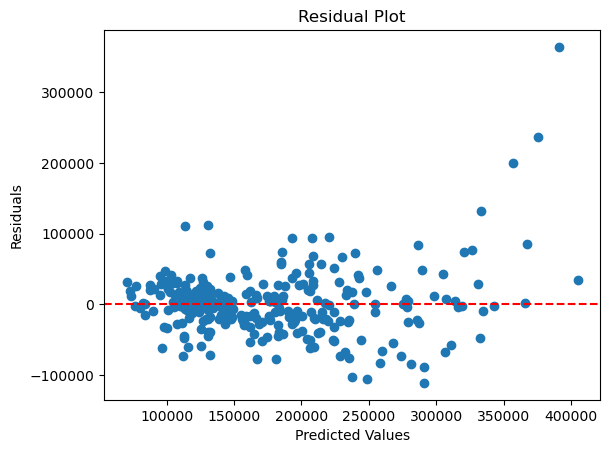

In [102]:
# Code Block 87
# calculate and plot residuals
residuals = y_test - preds
plt.scatter(preds, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [ ]:
# non constant variance

In [103]:
# Code Block 88: transforming data
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)
model.fit(X_train, y_train_log)
preds_log = model.predict(X_test)

In [104]:
# Code Block 89
preds = np.expm1(preds_log)

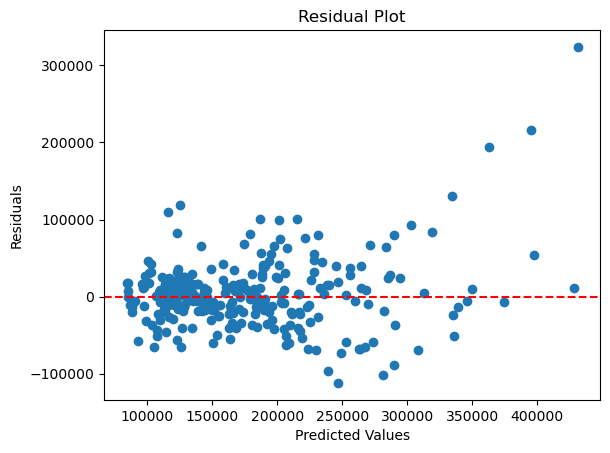

In [105]:
# Code Block 90
residuals = y_test - preds
plt.scatter(preds, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [106]:
# Code Block 91
# making a random forest
from sklearn.ensemble import RandomForestRegressor

In [107]:
# Code Block 92
model = RandomForestRegressor(random_state=42)
model.fit(X, y)
good_pred = pd.Series(model.feature_importances_, index=X.columns)
good_pred = good_pred.sort_values(ascending=False)
print(good_pred.head(20))

Fireplaces               0.223083
LotArea                  0.132477
MasVnrArea               0.125955
OpenPorchSF              0.124273
Foundation_CBlock        0.057697
Neighborhood_NridgHt     0.047625
WoodDeckSF               0.037639
SaleCondition_Partial    0.025404
Neighborhood_NoRidge     0.021654
GarageType_Detchd        0.017257
Neighborhood_StoneBr     0.017163
PoolArea                 0.016578
BsmtFullBath             0.014821
MSZoning_RM              0.010154
ScreenPorch              0.009858
EnclosedPorch            0.008604
HouseStyle_2Story        0.008174
HalfBath                 0.007569
Neighborhood_Somerst     0.007349
Neighborhood_Edwards     0.006770
dtype: float64
